# Odoo Weekly Sales Forecasting — Croston + Rolling Cross-Validation

This is a standalone notebook for **total weekly sales revenue** from Odoo.

It includes:

- weekly sales extraction from `sale_order`
- complete weekly calendar with missing weeks filled as zero
- intermittency diagnostics
- walk-forward baselines
- Croston and Syntetos-Boylan Approximation (SBA)
- rolling time-series cross-validation for parameter tuning
- walk-forward evaluation on the untouched test set
- fixed-horizon Croston comparison
- Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE)
- 12-week future forecast
- CSV exports

> Croston is naturally designed for intermittent demand quantity. Here we are deliberately testing whether it can also help when **weekly sales revenue itself is intermittent**.

## 1. PostgreSQL query

Run this in pgAdmin and export the result as `weekly_sales_revenue.csv`.

```sql
WITH params AS (
    SELECT
        DATE '2025-01-06' AS start_date,
        (
            DATE_TRUNC(
                'week',
                (CURRENT_TIMESTAMP AT TIME ZONE 'Asia/Kolkata')::date
            )::date - 1
        ) AS last_complete_sunday
),
sales AS (
    SELECT
        (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,
        so.id AS order_id,
        so.amount_total
    FROM sale_order so
    CROSS JOIN params p
    WHERE so.state IN ('sale', 'done')
      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date >= p.start_date
      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date <= p.last_complete_sunday
)
SELECT
    (DATE_TRUNC('week', sale_date)::date + 6) AS week_ending,
    SUM(amount_total) AS weekly_sales,
    COUNT(DISTINCT order_id) AS order_count
FROM sales
GROUP BY 1
ORDER BY week_ending;
```

This uses only complete weeks ending Sunday and confirmed sales orders.

## 2. Install packages

In [2]:
!pip install pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Imports

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

## 4. Load data

In [8]:
df = pd.read_csv(
    \"../input/../input/weekly_sales_history.csv\"
)

# Rename your sales column to the name used
# throughout the notebook
df = df.rename(
    columns={
        "weekly_sales_total": "weekly_sales"
    }
)

# Convert date
df["week_ending"] = pd.to_datetime(
    df["week_ending"]
)

# Convert sales to numeric
df["weekly_sales"] = pd.to_numeric(
    df["weekly_sales"],
    errors="coerce"
)

# Remove invalid rows
df = df.dropna(
    subset=[
        "week_ending",
        "weekly_sales"
    ]
)

# Sort chronologically
df = df.sort_values(
    "week_ending"
)

df.head()

,week_ending,weekly_sales
0,2025-01-12,7178815.12
1,2025-01-19,198122.40
2,2025-01-26,27064954.68
3,2025-02-02,63967214.68
4,2025-02-09,15832570.52


In [6]:
df = pd.read_csv(\"../input/../input/weekly_sales_history.csv\")

df = df.rename(
    columns={
        "weekly_sales_total": "weekly_sales"
    }
)

df.head()

,week_ending,weekly_sales
0,2025-01-12,7178815.12
1,2025-01-19,198122.40
2,2025-01-26,27064954.68
3,2025-02-02,63967214.68
4,2025-02-09,15832570.52


## 5. Clean data types

In [10]:
df["week_ending"] = pd.to_datetime(df["week_ending"])
df["weekly_sales"] = pd.to_numeric(df["weekly_sales"], errors="coerce")
# df["order_count"] = pd.to_numeric(df["order_count"], errors="coerce")

df = df.dropna(subset=["week_ending", "weekly_sales"])
df = df.sort_values("week_ending")  

print("Shape:", df.shape)
df.head()

Shape: (82, 2)


,week_ending,weekly_sales
0,2025-01-12,7178815.12
1,2025-01-19,198122.40
2,2025-01-26,27064954.68
3,2025-02-02,63967214.68
4,2025-02-09,15832570.52


## 6. Create complete weekly series

The SQL output contains weeks where sales exist. Missing calendar weeks are explicitly inserted and filled with `0.0`.

Only do this when a missing week truly means **no sales**, not missing source data.

In [11]:
all_weeks = pd.date_range(
    start=df["week_ending"].min(),
    end=df["week_ending"].max(),
    freq="W-SUN"
)

weekly_sales = (
    df.set_index("week_ending")["weekly_sales"]
      .reindex(all_weeks, fill_value=0.0)
)

weekly_sales.index.name = "week_ending"
weekly_sales.name = "weekly_sales"
weekly_sales.head(20)

week_ending
2025-01-12     7178815.12
2025-01-19      198122.40
2025-01-26    27064954.68
2025-02-02    63967214.68
2025-02-09    15832570.52
2025-02-16    14850112.48
2025-02-23    14801949.52
2025-03-02     4170065.72
2025-03-09     6615171.52
2025-03-16     7194944.12
2025-03-23    19326220.14
2025-03-30     4640314.62
2025-04-06     6189099.70
2025-04-13     8785451.08
2025-04-20     5082371.66
2025-04-27     7171929.50
2025-05-04     3655989.24
2025-05-11     4003634.04
2025-05-18     6314452.50
2025-05-25     3111636.02
Freq: W-SUN, Name: weekly_sales, dtype: float64

## 7. Inspect weekly sales

In [12]:
print(weekly_sales.describe())
print()
print("Weeks:", len(weekly_sales))
print("Zero-sales weeks:", int((weekly_sales == 0).sum()))
print("Zero-sales percentage:", round((weekly_sales == 0).mean() * 100, 2), "%")
print("Weeks with sales:", int((weekly_sales > 0).sum()))

count    8.200000e+01
mean     5.005179e+06
std      8.767173e+06
min      0.000000e+00
25%      3.492731e+05
50%      2.030684e+06
75%      6.103794e+06
max      6.396721e+07
Name: weekly_sales, dtype: float64

Weeks: 82
Zero-sales weeks: 3
Zero-sales percentage: 3.66 %
Weeks with sales: 79


## 8. Plot weekly sales

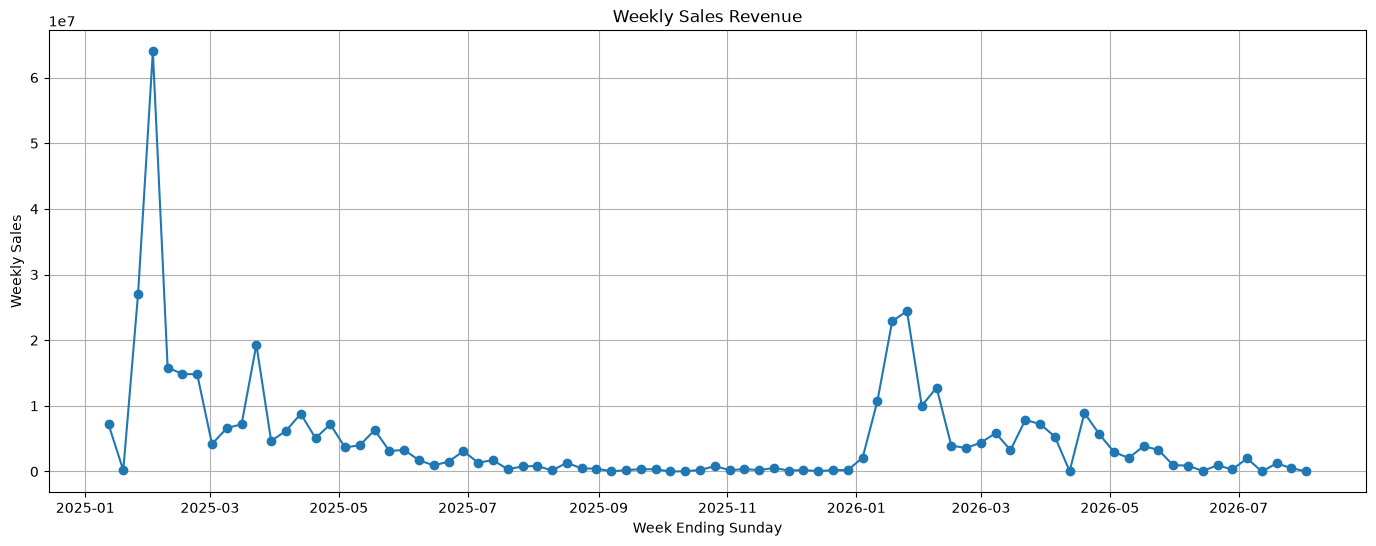

In [13]:
plt.figure(figsize=(17, 6))
plt.plot(weekly_sales.index, weekly_sales.values, marker="o")
plt.title("Weekly Sales Revenue")
plt.xlabel("Week Ending Sunday")
plt.ylabel("Weekly Sales")
plt.grid(True)
plt.show()

# Intermittency diagnostics

We calculate:

- **Average Demand Interval (ADI)** = average number of weeks per non-zero sales occurrence
- **CV²** = squared coefficient of variation of non-zero weekly sales

A common classification uses thresholds ADI = 1.32 and CV² = 0.49.

## 9. Calculate ADI and CV²

In [14]:
nonzero_sales = weekly_sales[weekly_sales > 0]
nonzero_count = len(nonzero_sales)

if nonzero_count > 0:
    ADI = len(weekly_sales) / nonzero_count
    mean_nonzero = nonzero_sales.mean()
    std_nonzero = nonzero_sales.std(ddof=1) if nonzero_count > 1 else 0.0
    CV2 = (std_nonzero / mean_nonzero) ** 2 if mean_nonzero != 0 else np.nan
else:
    ADI = np.inf
    CV2 = np.nan

print("Average Demand Interval (ADI):", round(ADI, 3))
print("Squared coefficient of variation (CV²):", round(CV2, 3))

Average Demand Interval (ADI): 1.038
Squared coefficient of variation (CV²): 2.92


## 10. Classify the weekly sales pattern

In [15]:
if np.isnan(CV2):
    demand_pattern = "Undefined"
elif ADI < 1.32 and CV2 < 0.49:
    demand_pattern = "Smooth"
elif ADI < 1.32 and CV2 >= 0.49:
    demand_pattern = "Erratic"
elif ADI >= 1.32 and CV2 < 0.49:
    demand_pattern = "Intermittent"
else:
    demand_pattern = "Lumpy"

print("Weekly sales pattern:", demand_pattern)

if demand_pattern in ["Intermittent", "Lumpy"]:
    print("Croston-family methods are reasonable to test.")
else:
    print("Croston can still be tested, but ARIMA or Exponential Smoothing may be more natural.")

Weekly sales pattern: Erratic
Croston can still be tested, but ARIMA or Exponential Smoothing may be more natural.


# Train/Test split

The final test block stays untouched during rolling cross-validation.

## 11. Split data

In [16]:
series = weekly_sales.copy()

if len(series) >= 40:
    test_size = min(12, max(8, len(series) // 5))
else:
    test_size = max(4, len(series) // 5)

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training weeks:", len(train))
print("Testing weeks:", len(test))
print("Train:", train.index.min(), "->", train.index.max())
print("Test :", test.index.min(), "->", test.index.max())

Training weeks: 70
Testing weeks: 12
Train: 2025-01-12 00:00:00 -> 2026-05-10 00:00:00
Test : 2026-05-17 00:00:00 -> 2026-08-02 00:00:00


## 12. Plot train/test split

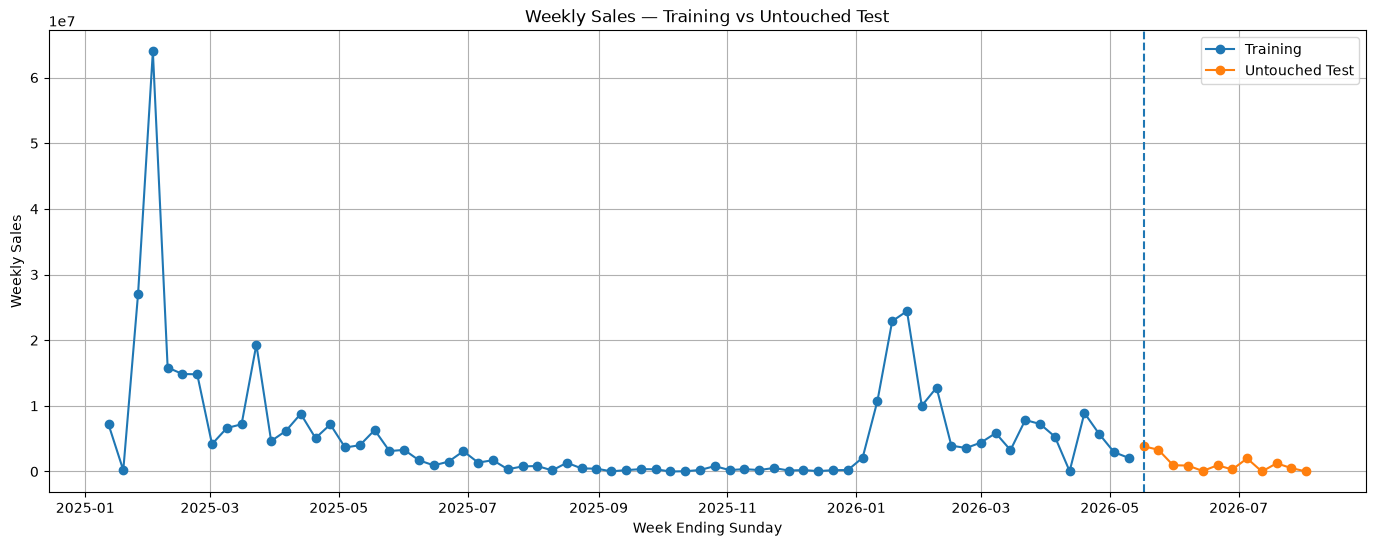

In [17]:
plt.figure(figsize=(17, 6))
plt.plot(train.index, train.values, marker="o", label="Training")
plt.plot(test.index, test.values, marker="o", label="Untouched Test")
plt.axvline(test.index.min(), linestyle="--")
plt.title("Weekly Sales — Training vs Untouched Test")
plt.xlabel("Week Ending Sunday")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

# Error metrics

- **Mean Absolute Error (MAE)**: average absolute error
- **Root Mean Squared Error (RMSE)**: gives more penalty to large errors
- **Weighted Absolute Percentage Error (WAPE)**: total absolute error divided by total actual sales

Lower is better.

## 13. Metric functions

In [18]:
def wape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.sum(np.abs(actual))
    if denominator == 0:
        return np.nan
    return (np.sum(np.abs(actual - predicted)) / denominator) * 100


def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE": wape(actual, predicted)
    }


def evaluate_model(actual, predicted, name):
    metrics = get_metrics(actual, predicted)
    print(name)
    print("-" * 55)
    print(f"Mean Absolute Error: {metrics['MAE']:,.3f}")
    print(f"Root Mean Squared Error: {metrics['RMSE']:,.3f}")
    print(f"Weighted Absolute Percentage Error: {metrics['WAPE']:.2f}%")
    return metrics

# Fair walk-forward baselines

The baselines are updated after every newly observed test week, just like the Croston-family model.

## 14. Walk-forward Last-Week Naive

In [19]:
def walk_forward_last_week(train, test):
    history = list(train.values)
    predictions = []
    for actual in test.values:
        predictions.append(history[-1])
        history.append(float(actual))
    return np.asarray(predictions, dtype=float)

wf_last_week = walk_forward_last_week(train, test)
evaluate_model(test, wf_last_week, "Walk-Forward Last-Week Naive")

Walk-Forward Last-Week Naive
-------------------------------------------------------
Mean Absolute Error: 1,104,139.877
Root Mean Squared Error: 1,293,714.240
Weighted Absolute Percentage Error: 94.00%


{'MAE': 1104139.8766666667,
 'RMSE': np.float64(1293714.2402439485),
 'WAPE': np.float64(93.99891766523572)}

## 15. Walk-forward Four-Week Mean

In [20]:
def walk_forward_four_week_mean(train, test):
    history = list(train.values)
    predictions = []
    for actual in test.values:
        predictions.append(np.mean(history[-4:]))
        history.append(float(actual))
    return np.asarray(predictions, dtype=float)

wf_four_week_mean = walk_forward_four_week_mean(train, test)
evaluate_model(test, wf_four_week_mean, "Walk-Forward Four-Week Mean")

Walk-Forward Four-Week Mean
-------------------------------------------------------
Mean Absolute Error: 1,008,130.236
Root Mean Squared Error: 1,200,895.337
Weighted Absolute Percentage Error: 85.83%


{'MAE': 1008130.23625,
 'RMSE': np.float64(1200895.3371082428),
 'WAPE': np.float64(85.82531350935604)}

## 16. Walk-forward Four-Week Median

In [21]:
def walk_forward_four_week_median(train, test):
    history = list(train.values)
    predictions = []
    for actual in test.values:
        predictions.append(np.median(history[-4:]))
        history.append(float(actual))
    return np.asarray(predictions, dtype=float)

wf_four_week_median = walk_forward_four_week_median(train, test)
evaluate_model(test, wf_four_week_median, "Walk-Forward Four-Week Median")

Walk-Forward Four-Week Median
-------------------------------------------------------
Mean Absolute Error: 917,890.886
Root Mean Squared Error: 1,166,149.233
Weighted Absolute Percentage Error: 78.14%


{'MAE': 917890.8858333332,
 'RMSE': np.float64(1166149.232943579),
 'WAPE': np.float64(78.14295237990522)}

# Croston and Syntetos-Boylan Approximation

Croston estimates the non-zero event size and the interval between events. The Syntetos-Boylan Approximation applies a bias correction.

## 17. Croston / SBA implementation

In [22]:
def croston_fit(series, alpha=0.1, variant="classic"):
    y = np.asarray(series, dtype=float)

    if len(y) == 0:
        raise ValueError("Series must not be empty.")

    nonzero_idx = np.flatnonzero(y > 0)

    if len(nonzero_idx) == 0:
        return {
            "forecast": 0.0,
            "sales_estimate": 0.0,
            "interval_estimate": np.inf,
            "alpha": float(alpha),
            "variant": variant
        }

    first = nonzero_idx[0]
    z = y[first]
    p = first + 1
    interval = 1

    for t in range(first + 1, len(y)):
        if y[t] > 0:
            z = alpha * y[t] + (1 - alpha) * z
            p = alpha * interval + (1 - alpha) * p
            interval = 1
        else:
            interval += 1

    forecast = z / p

    if variant.lower() == "sba":
        forecast = (1 - alpha / 2) * forecast

    return {
        "forecast": max(float(forecast), 0.0),
        "sales_estimate": float(z),
        "interval_estimate": float(p),
        "alpha": float(alpha),
        "variant": variant
    }

## 18. Initial Croston and SBA at alpha = 0.1

In [23]:
initial_croston = croston_fit(train, alpha=0.1, variant="classic")
initial_sba = croston_fit(train, alpha=0.1, variant="sba")

print("Initial Croston:", initial_croston)
print("Initial SBA:", initial_sba)

Initial Croston: {'forecast': 5168033.452618576, 'sales_estimate': 5189941.345024735, 'interval_estimate': 1.0042391158275221, 'alpha': 0.1, 'variant': 'classic'}
Initial SBA: {'forecast': 4909631.779987646, 'sales_estimate': 5189941.345024735, 'interval_estimate': 1.0042391158275221, 'alpha': 0.1, 'variant': 'sba'}


# Rolling time-series cross-validation

We test 10 alpha values (`0.05` through `0.50`) for both Classic Croston and SBA.

Each candidate combination is evaluated across multiple progressive folds.

## 19. Rolling cross-validation function

In [24]:
def rolling_cv_croston(
    train,
    alpha_grid,
    variants=("classic", "sba"),
    initial_train_weeks=30,
    validation_weeks=4,
    step_weeks=4
):
    summary_rows = []
    fold_detail_rows = []

    for variant in variants:
        for alpha in alpha_grid:
            fold_metrics = []
            train_end = initial_train_weeks
            fold_number = 1

            while train_end + validation_weeks <= len(train):
                fold_train = train.iloc[:train_end]
                fold_validation = train.iloc[
                    train_end:train_end + validation_weeks
                ]

                model = croston_fit(
                    fold_train,
                    alpha=float(alpha),
                    variant=variant
                )

                predictions = np.repeat(
                    model["forecast"],
                    len(fold_validation)
                )

                metrics = get_metrics(
                    fold_validation,
                    predictions
                )

                fold_metrics.append(metrics)

                fold_detail_rows.append({
                    "variant": variant,
                    "alpha": float(alpha),
                    "fold": fold_number,
                    "train_start": fold_train.index.min(),
                    "train_end": fold_train.index.max(),
                    "validation_start": fold_validation.index.min(),
                    "validation_end": fold_validation.index.max(),
                    "MAE": metrics["MAE"],
                    "RMSE": metrics["RMSE"],
                    "WAPE": metrics["WAPE"]
                })

                train_end += step_weeks
                fold_number += 1

            if fold_metrics:
                fold_df = pd.DataFrame(fold_metrics)
                summary_rows.append({
                    "variant": variant,
                    "alpha": float(alpha),
                    "folds": len(fold_df),
                    "mean_MAE": fold_df["MAE"].mean(),
                    "mean_RMSE": fold_df["RMSE"].mean(),
                    "mean_WAPE": fold_df["WAPE"].mean(),
                    "median_WAPE": fold_df["WAPE"].median(),
                    "std_WAPE": fold_df["WAPE"].std()
                })

    summary = (
        pd.DataFrame(summary_rows)
        .sort_values("mean_WAPE")
        .reset_index(drop=True)
    )

    fold_details = pd.DataFrame(fold_detail_rows)
    return summary, fold_details

## 20. Run rolling cross-validation

In [25]:
alpha_grid = np.arange(0.05, 0.55, 0.05)

INITIAL_TRAIN_WEEKS = min(
    30,
    max(12, len(train) // 2)
)

VALIDATION_WEEKS = 4
STEP_WEEKS = 4

rolling_results, rolling_fold_details = rolling_cv_croston(
    train=train,
    alpha_grid=alpha_grid,
    initial_train_weeks=INITIAL_TRAIN_WEEKS,
    validation_weeks=VALIDATION_WEEKS,
    step_weeks=STEP_WEEKS
)

rolling_results

,variant,alpha,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE,std_WAPE
0,sba,0.50,10,2.431011e+06,3.146503e+06,69.765867,66.659170,22.831559
1,sba,0.45,10,2.467816e+06,3.186901e+06,72.768803,70.028779,24.099994
2,sba,0.40,10,2.515356e+06,3.233561e+06,76.180764,79.536121,27.093307
3,sba,0.35,10,2.588175e+06,3.286549e+06,80.606121,89.002372,31.690390
4,sba,0.30,10,2.654474e+06,3.347847e+06,86.313660,96.597118,39.379370
5,classic,0.50,10,2.684639e+06,3.292497e+06,91.184996,91.311279,40.663029
6,classic,0.45,10,2.668119e+06,3.305660e+06,92.016913,92.949970,42.871390
7,classic,0.40,10,2.674166e+06,3.334302e+06,93.424096,95.284729,45.803303
8,sba,0.25,10,2.711151e+06,3.422772e+06,95.031396,100.496851,53.364085
9,classic,0.35,10,2.691838e+06,3.379382e+06,95.660926,98.676759,49.863243


## 21. Show combinations, folds, and total evaluations

In [26]:
number_of_alphas = len(alpha_grid)
number_of_variants = 2
number_of_combinations = number_of_alphas * number_of_variants
number_of_folds = int(rolling_results["folds"].iloc[0])
total_evaluations = number_of_combinations * number_of_folds

print("Alpha values:", number_of_alphas)
print("Model variants:", number_of_variants)
print("Combinations:", number_of_combinations)
print("Folds per combination:", number_of_folds)
print("Total model evaluations:", total_evaluations)

Alpha values: 10
Model variants: 2
Combinations: 20
Folds per combination: 10
Total model evaluations: 200


## 22. Select best Croston-family configuration

In [27]:
best_cv_row = rolling_results.iloc[0]
best_variant = best_cv_row["variant"]
best_alpha = float(best_cv_row["alpha"])

print("Best variant:", best_variant.upper())
print("Best alpha:", best_alpha)
print("Number of folds:", int(best_cv_row["folds"]))
print("Average CV WAPE:", round(best_cv_row["mean_WAPE"], 2), "%")
print("Median CV WAPE:", round(best_cv_row["median_WAPE"], 2), "%")
print("CV WAPE standard deviation:", round(best_cv_row["std_WAPE"], 2))

Best variant: SBA
Best alpha: 0.5
Number of folds: 10
Average CV WAPE: 69.77 %
Median CV WAPE: 66.66 %
CV WAPE standard deviation: 22.83


## 23. Inspect the winning combination fold-by-fold

In [28]:
best_fold_details = rolling_fold_details[
    (rolling_fold_details["variant"] == best_variant)
    & np.isclose(rolling_fold_details["alpha"], best_alpha)
].reset_index(drop=True)

best_fold_details

,variant,alpha,fold,train_start,train_end,validation_start,validation_end,MAE,RMSE,WAPE
0,sba,0.5,1,2025-01-12,2025-08-03,2025-08-10,2025-08-31,3.964925e+05,4.426514e+05,66.217925
1,sba,0.5,2,2025-01-12,2025-08-31,2025-09-07,2025-09-28,1.908125e+05,2.330060e+05,82.203060
2,sba,0.5,3,2025-01-12,2025-09-28,2025-10-05,2025-10-26,2.599246e+05,3.297262e+05,95.734486
3,sba,0.5,4,2025-01-12,2025-10-26,2025-11-02,2025-11-23,1.131753e+05,1.290587e+05,34.154007
4,sba,0.5,5,2025-01-12,2025-11-23,2025-11-30,2025-12-21,1.508303e+05,1.621777e+05,97.178380
5,sba,0.5,6,2025-01-12,2025-12-21,2025-12-28,2026-01-18,8.856281e+06,1.259618e+07,98.532882
6,sba,0.5,7,2025-01-12,2026-01-18,2026-01-25,2026-02-15,5.814312e+06,7.698809e+06,45.471704
7,sba,0.5,8,2025-01-12,2026-02-15,2026-02-22,2026-03-15,2.358199e+06,2.561820e+06,55.198963
8,sba,0.5,9,2025-01-12,2026-03-15,2026-03-22,2026-04-12,3.427983e+06,3.554061e+06,67.100415
9,sba,0.5,10,2025-01-12,2026-04-12,2026-04-19,2026-05-10,2.742100e+06,3.757541e+06,55.866850


## 24. Plot WAPE by fold

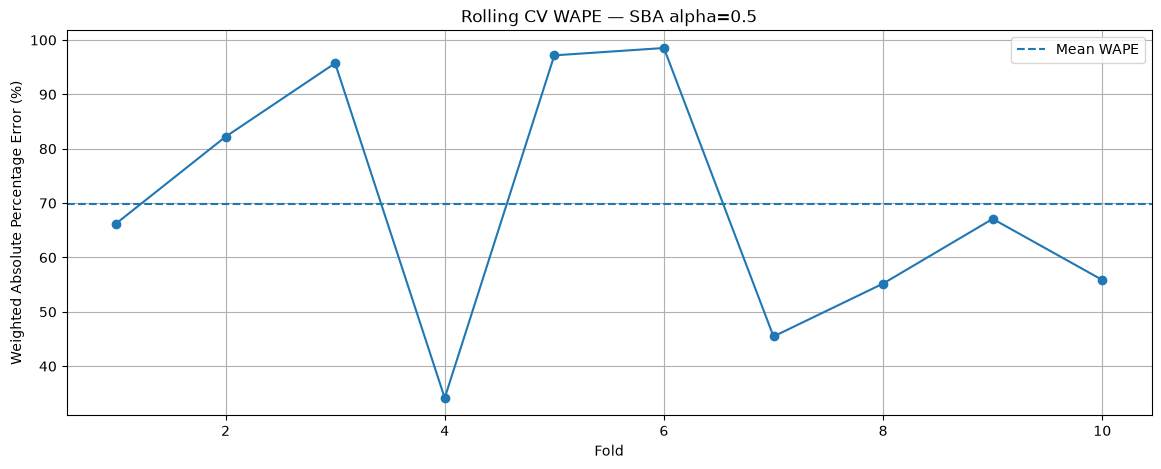

In [29]:
plt.figure(figsize=(14, 5))
plt.plot(
    best_fold_details["fold"],
    best_fold_details["WAPE"],
    marker="o"
)
plt.axhline(
    best_fold_details["WAPE"].mean(),
    linestyle="--",
    label="Mean WAPE"
)
plt.title(
    f"Rolling CV WAPE — {best_variant.upper()} alpha={best_alpha}"
)
plt.xlabel("Fold")
plt.ylabel("Weighted Absolute Percentage Error (%)")
plt.legend()
plt.grid(True)
plt.show()

# Final untouched-test evaluation

We now compare two Croston-family evaluation modes:

- **Walk-forward**: update after every observed test week
- **Fixed horizon**: train once, then repeat the same Croston sales-rate estimate across the whole test horizon

## 25. Walk-forward Croston-family function

In [30]:
def walk_forward_croston(train, test, alpha, variant):
    history = list(train.values)
    predictions = []

    for actual in test.values:
        model = croston_fit(
            history,
            alpha=alpha,
            variant=variant
        )
        predictions.append(model["forecast"])
        history.append(float(actual))

    return np.asarray(predictions, dtype=float)

## 26. Walk-forward selected Croston/SBA

In [31]:
wf_croston_selected = walk_forward_croston(
    train=train,
    test=test,
    alpha=best_alpha,
    variant=best_variant
)

evaluate_model(
    test,
    wf_croston_selected,
    "Rolling CV + Walk-Forward " + best_variant.upper()
)

Rolling CV + Walk-Forward SBA
-------------------------------------------------------
Mean Absolute Error: 805,707.205
Root Mean Squared Error: 946,473.113
Weighted Absolute Percentage Error: 68.59%


{'MAE': 805707.2048803373,
 'RMSE': np.float64(946473.1134026861),
 'WAPE': np.float64(68.59240103027106)}

## 27. Fixed-horizon selected Croston/SBA

In [32]:
fixed_model = croston_fit(
    train,
    alpha=best_alpha,
    variant=best_variant
)

fixed_croston_predictions = np.repeat(
    fixed_model["forecast"],
    len(test)
)

evaluate_model(
    test,
    fixed_croston_predictions,
    "Rolling CV + Fixed " + best_variant.upper()
)

Rolling CV + Fixed SBA
-------------------------------------------------------
Mean Absolute Error: 1,632,277.717
Root Mean Squared Error: 1,741,019.241
Weighted Absolute Percentage Error: 138.96%


{'MAE': 1632277.7167921867,
 'RMSE': np.float64(1741019.2410269051),
 'WAPE': np.float64(138.960961332862)}

## 28. Final fair comparison

In [33]:
comparison_metrics = pd.DataFrame([
    {
        "Model": "Walk-Forward Last-Week Naive",
        **get_metrics(test, wf_last_week)
    },
    {
        "Model": "Walk-Forward Four-Week Mean",
        **get_metrics(test, wf_four_week_mean)
    },
    {
        "Model": "Walk-Forward Four-Week Median",
        **get_metrics(test, wf_four_week_median)
    },
    {
        "Model": "Rolling CV + Walk-Forward " + best_variant.upper(),
        **get_metrics(test, wf_croston_selected)
    },
    {
        "Model": "Rolling CV + Fixed " + best_variant.upper(),
        **get_metrics(test, fixed_croston_predictions)
    }
])

comparison_metrics = (
    comparison_metrics
    .sort_values("WAPE")
    .reset_index(drop=True)
)

comparison_metrics

,Model,MAE,RMSE,WAPE
0,Rolling CV + Walk-Forward SBA,8.057072e+05,9.464731e+05,68.592401
1,Walk-Forward Four-Week Median,9.178909e+05,1.166149e+06,78.142952
2,Walk-Forward Four-Week Mean,1.008130e+06,1.200895e+06,85.825314
3,Walk-Forward Last-Week Naive,1.104140e+06,1.293714e+06,93.998918
4,Rolling CV + Fixed SBA,1.632278e+06,1.741019e+06,138.960961


## 29. Identify final winner

In [34]:
winner = comparison_metrics.iloc[0]

print("Best final test model:", winner["Model"])
print("Final test WAPE:", round(winner["WAPE"], 2), "%")
print("Final test MAE:", round(winner["MAE"], 3))
print("Final test RMSE:", round(winner["RMSE"], 3))

Best final test model: Rolling CV + Walk-Forward SBA
Final test WAPE: 68.59 %
Final test MAE: 805707.205
Final test RMSE: 946473.113


## 30. Plot actual vs walk-forward forecasts

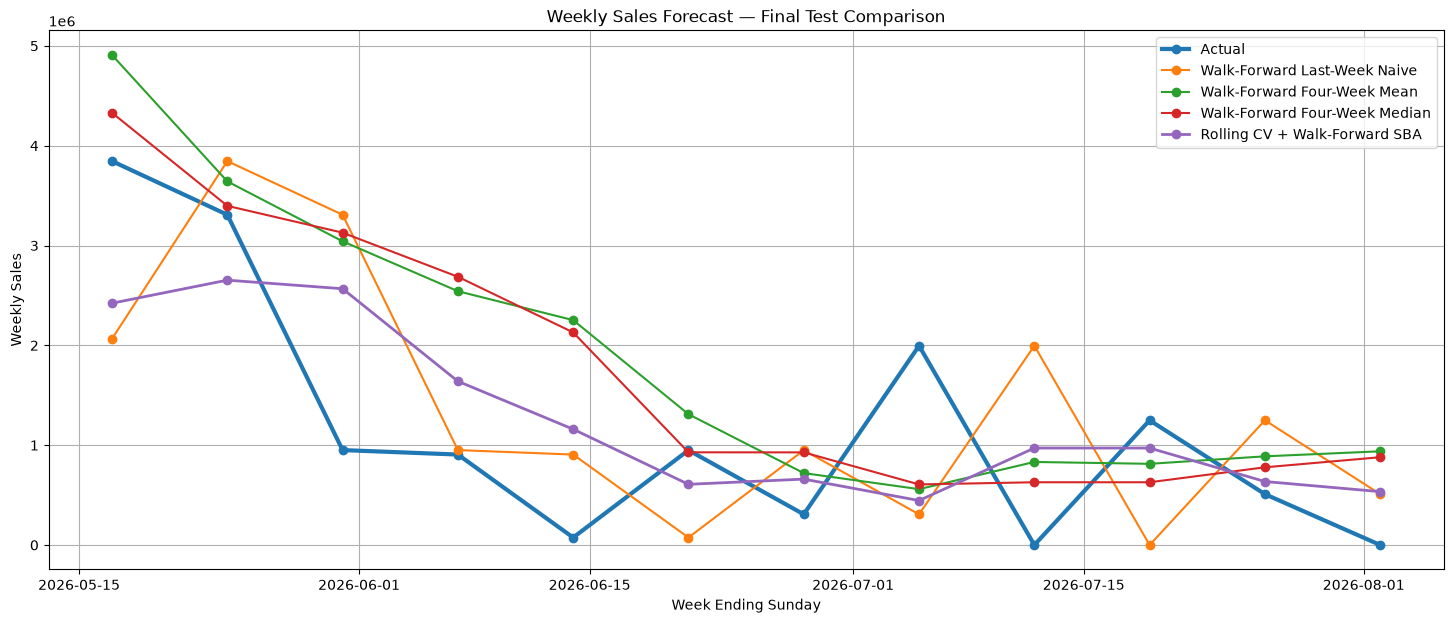

In [35]:
plt.figure(figsize=(18, 7))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    test.index,
    wf_last_week,
    marker="o",
    label="Walk-Forward Last-Week Naive"
)

plt.plot(
    test.index,
    wf_four_week_mean,
    marker="o",
    label="Walk-Forward Four-Week Mean"
)

plt.plot(
    test.index,
    wf_four_week_median,
    marker="o",
    label="Walk-Forward Four-Week Median"
)

plt.plot(
    test.index,
    wf_croston_selected,
    marker="o",
    linewidth=2,
    label="Rolling CV + Walk-Forward " + best_variant.upper()
)

plt.title("Weekly Sales Forecast — Final Test Comparison")
plt.xlabel("Week Ending Sunday")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

## 31. Detailed prediction table

In [36]:
final_test_predictions = pd.DataFrame({
    "actual": test.values,
    "walk_forward_last_week": wf_last_week,
    "walk_forward_four_week_mean": wf_four_week_mean,
    "walk_forward_four_week_median": wf_four_week_median,
    "rolling_cv_walk_forward_croston_family": wf_croston_selected,
    "rolling_cv_fixed_croston_family": fixed_croston_predictions
}, index=test.index)

final_test_predictions

,actual,walk_forward_last_week,walk_forward_four_week_mean,walk_forward_four_week_median,rolling_cv_walk_forward_croston_family,rolling_cv_fixed_croston_family
week_ending,,,,,,
2026-05-17,3845120.16,2065542.20,4908277.595,4329226.77,2.422091e+06,2.422091e+06
2026-05-24,3307965.28,3845120.16,3642278.975,3397183.78,2.652965e+06,2.422091e+06
2026-05-31,950716.32,3307965.28,3041968.760,3128606.34,2.566970e+06,2.422091e+06
2026-06-07,906025.08,950716.32,2542335.990,2686753.74,1.640003e+06,2.422091e+06
2026-06-14,74626.68,906025.08,2252456.710,2129340.80,1.159761e+06,2.422091e+06
2026-06-21,949571.74,74626.68,1309833.340,928370.70,6.078656e+05,2.422091e+06
2026-06-28,307389.60,949571.74,720234.955,927798.41,6.600222e+05,2.422091e+06
2026-07-05,1995826.38,307389.60,559403.275,606707.34,4.452822e+05,2.422091e+06
2026-07-12,0.00,1995826.38,831853.600,628480.67,9.710760e+05,2.422091e+06


# Future forecast

After evaluation, fit the selected Croston-family configuration on all complete historical weeks.

A fixed Croston-family multi-step forecast is normally flat because it represents an expected sales rate. If you rerun the model every week, the estimate can change when new actual sales arrive.

## 32. Fit final model on all history

In [37]:
final_model = croston_fit(
    series,
    alpha=best_alpha,
    variant=best_variant
)

final_model

{'forecast': 534346.0660613808,
 'sales_estimate': 890576.776769292,
 'interval_estimate': 1.2500000000004547,
 'alpha': 0.5,
 'variant': 'sba'}

## 33. Forecast next 12 weeks

In [38]:
FORECAST_WEEKS = 12

future_dates = pd.date_range(
    start=series.index.max() + pd.Timedelta(weeks=1),
    periods=FORECAST_WEEKS,
    freq="W-SUN"
)

future_predictions = np.repeat(
    final_model["forecast"],
    FORECAST_WEEKS
)

future_df = pd.DataFrame({
    "week_ending": future_dates,
    "forecast_weekly_sales": future_predictions,
    "model": best_variant.upper(),
    "alpha": best_alpha
})

future_df

,week_ending,forecast_weekly_sales,model,alpha
0,2026-08-09,534346.066061,SBA,0.5
1,2026-08-16,534346.066061,SBA,0.5
2,2026-08-23,534346.066061,SBA,0.5
3,2026-08-30,534346.066061,SBA,0.5
4,2026-09-06,534346.066061,SBA,0.5
5,2026-09-13,534346.066061,SBA,0.5
6,2026-09-20,534346.066061,SBA,0.5
7,2026-09-27,534346.066061,SBA,0.5
8,2026-10-04,534346.066061,SBA,0.5
9,2026-10-11,534346.066061,SBA,0.5


## 34. Plot future forecast

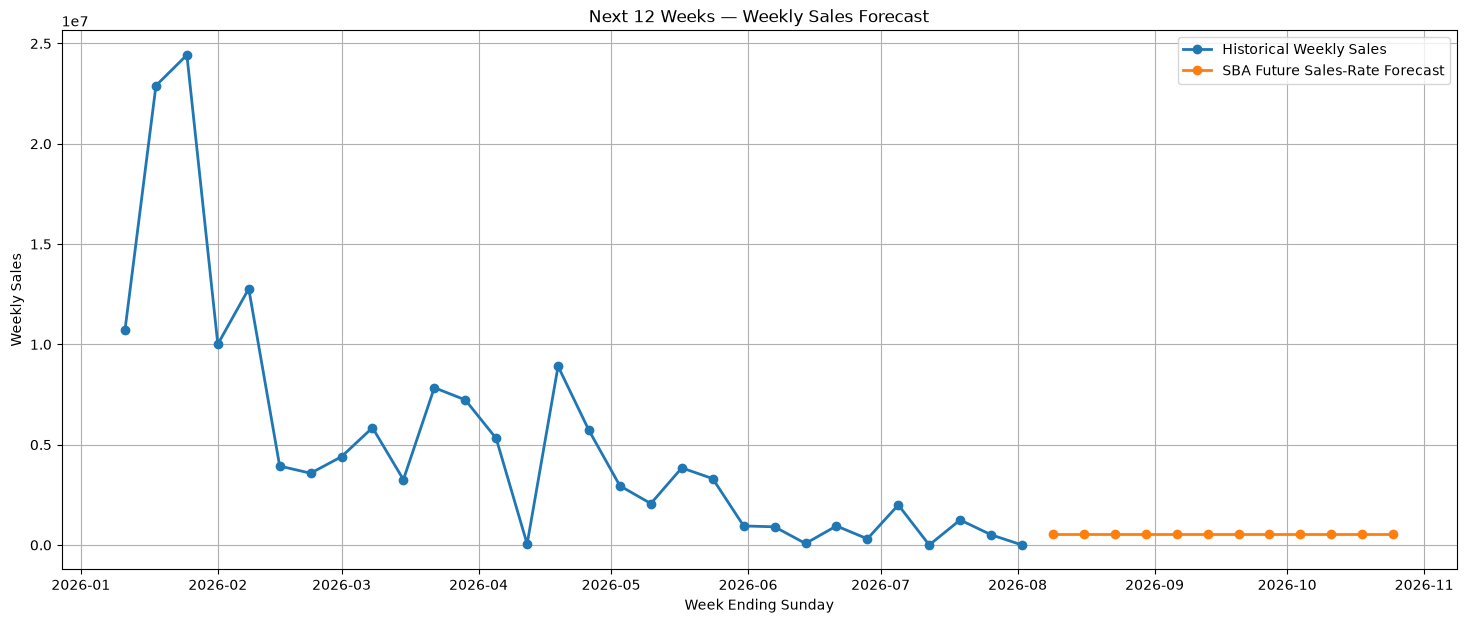

In [39]:
plt.figure(figsize=(18, 7))

recent_history = series.tail(30)

plt.plot(
    recent_history.index,
    recent_history.values,
    marker="o",
    linewidth=2,
    label="Historical Weekly Sales"
)

plt.plot(
    future_df["week_ending"],
    future_df["forecast_weekly_sales"],
    marker="o",
    linewidth=2,
    label=best_variant.upper() + " Future Sales-Rate Forecast"
)

plt.title(f"Next {FORECAST_WEEKS} Weeks — Weekly Sales Forecast")
plt.xlabel("Week Ending Sunday")
plt.ylabel("Weekly Sales")
plt.legend()
plt.grid(True)
plt.show()

## 35. Export results

In [40]:
comparison_metrics.to_csv(
    "weekly_sales_model_comparison.csv",
    index=False
)

rolling_results.to_csv(
    "weekly_sales_rolling_cv_results.csv",
    index=False
)

best_fold_details.to_csv(
    "weekly_sales_best_cv_fold_details.csv",
    index=False
)

final_test_predictions.to_csv(
    "weekly_sales_final_test_predictions.csv"
)

future_df.to_csv(
    "weekly_sales_12_week_forecast.csv",
    index=False
)

print("Exported all weekly sales forecasting results.")

Exported all weekly sales forecasting results.


# How to interpret the result

Inspect these outputs in order:

1. zero-sales percentage
2. Average Demand Interval and pattern classification
3. rolling cross-validation table
4. selected Croston/SBA variant and alpha
5. final walk-forward test metrics
6. comparison against walk-forward baselines

The main decision table is:

```python
comparison_metrics
```

Do **not** choose Croston just because the weekly series contains some zeros. Choose it only if its untouched-test performance is better than the simpler baselines.